<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week5/lesson19/Lesson19_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 19 — Bayesian Inference and Decisions: Priors, Posteriors and Costs

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 5 — Probability\
**Lesson:** Lesson 19\
**Notebook type:** Teaching notebook

> *"A posterior is only as trustworthy as the model that produced it."*

---

### From likelihood to belief

Lesson 18 asked how probable the data are for each value of a parameter (the likelihood). The question a scientist or a brain usually needs answered is the reverse: **given the data, how probable is each hypothesis?** Bayes' rule answers it by combining the likelihood with a **prior**. A decision then weighs those probabilities against the **costs** of each kind of error.

We will see:
1. **Bayes' rule** and normalisation, for discrete hypotheses;
2. **odds and likelihood ratios**, and how independent pieces of evidence accumulate **sequentially** (the logic of evidence-accumulation models of decision making);
3. **posterior distributions** over a continuous parameter from a **generative model**, with the beta–binomial and gamma–Poisson examples;
4. summarising a posterior: **MAP**, **posterior mean** and posterior probabilities;
5. **decisions**: expected loss, optimal thresholds, and **calibration** (do probabilities of 0.9 come true 90% of the time?).

The mini-lab revisits the mouse of Lessons 16–18 ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x)): Bayesian estimates of its choice probabilities, including the levels where Lesson 18's estimates broke down, and a Bayesian decoder of the stimulus from 66 V1 neurons that is 98% accurate and badly miscalibrated.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy import stats
from scipy.special import gammaln, expit

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-18.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-18.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: You Have Already Used Bayes' Rule**

In Lesson 16, a spike detector had sensitivity 0.9 and specificity 0.9, and real spikes occupied 1% of the windows scanned. We asked: when the detector says "spike", how likely is it to be right?

- $P(\text{spike and alarm}) = 0.9 \times 0.01 = 0.009$ (product rule).
- $P(\text{alarm}) = 0.9 \times 0.01 + 0.1 \times 0.99 = 0.108$ (law of total probability).
- $P(\text{spike} \mid \text{alarm}) = 0.009/0.108 \approx 0.083$.

That computation **is** Bayes' rule: it turned $P(\text{alarm} \mid \text{spike})$, a property of the detector, into $P(\text{spike} \mid \text{alarm})$, what we want to know, using the **prior** probability of a spike, 0.01.

**Prediction before running:** the detector fires twice, on two independent looks at the same window. Is the window now more likely than not to contain a spike?

In [3]:
prior, sens, spec = 0.01, 0.9, 0.9
post1 = sens * prior / (sens * prior + (1 - spec) * (1 - prior))
post2 = sens * post1 / (sens * post1 + (1 - spec) * (1 - post1))           # yesterday's posterior is today's prior
print(f"after one alarm: P(spike | alarm) = {post1:.3f};  after a second independent alarm: {post2:.3f}")

after one alarm: P(spike | alarm) = 0.083;  after a second independent alarm: 0.450


One alarm raises the probability from 1% to 8%; a second independent alarm raises it to 45%, still not more likely than not. Each alarm multiplies the **odds** by the same factor, 9 (Part 2 explains why). A third alarm would take it to 88%.

# **Part 1: Bayes' Rule and Normalisation**

For hypotheses $H_1, \dots, H_m$ that partition the possibilities (exactly one is true) and observed data $D$, the product rule written two ways, $P(H_i \cap D) = P(D \mid H_i)P(H_i) = P(H_i \mid D)P(D)$, gives **Bayes' rule**:

$$\underbrace{P(H_i \mid D)}_{\text{posterior}} = \frac{\overbrace{P(D \mid H_i)}^{\text{likelihood}}\ \overbrace{P(H_i)}^{\text{prior}}}{\underbrace{P(D)}_{\text{evidence}}},\qquad P(D) = \sum_{j=1}^{m} P(D \mid H_j)\,P(H_j).$$

- The **evidence** $P(D)$ is the law of total probability (Lesson 16). It does not depend on $i$: it only **normalises** the posterior so it sums to 1. In practice: multiply likelihood by prior for every hypothesis, then divide by the sum.
- The likelihood $P(D \mid H_i)$ comes from a **generative model**: a description of how data are produced under each hypothesis (Lesson 18's distributions).
- The prior $P(H_i)$ is what was known before the data: a base rate, the frequency of stimuli in an experiment, or earlier data.
- **Posterior ∝ likelihood × prior.** With a flat prior, the posterior is the normalised likelihood, and the most probable hypothesis is the maximum-likelihood one.

**Example: decoding orientation from one response.** An orientation-tuned neuron (the neuron of Lesson 16's exercises) responds "low", "medium" or "high". Its encoding model $P(\text{response} \mid \text{orientation})$ is below. Which orientation was shown, given a "high" response, when orientations are equally likely, and when 90° is rare?

In [4]:
def posterior(prior, likelihood):
    # Bayes' rule for discrete hypotheses: prior (m,), likelihood (m,) = P(data | each hypothesis). Returns the posterior (m,).
    prior, likelihood = np.asarray(prior, float), np.asarray(likelihood, float)
    if prior.shape != likelihood.shape or np.any(prior < 0) or not np.isclose(prior.sum(), 1):
        raise ValueError("prior must be a probability vector with the same shape as the likelihood")
    unnorm = likelihood * prior
    evidence = unnorm.sum()                                                 # P(D), by the law of total probability
    if evidence == 0:
        raise ValueError("the data are impossible under every hypothesis")
    return unnorm / evidence

oris = np.array([0, 45, 90, 135])                                          # degrees
enc = np.array([[0.70, 0.25, 0.05],                                        # P(low, medium, high | 0 degrees)
                [0.30, 0.45, 0.25],
                [0.05, 0.25, 0.70],
                [0.30, 0.45, 0.25]])                                       # (4 orientations, 3 responses); rows sum to 1
lik_high = enc[:, 2]                                                       # (4,) P(high | each orientation)
for name, pr in [('equal prior', np.full(4, 0.25)), ('90 deg rare (prior 0.04)', np.array([0.32, 0.32, 0.04, 0.32]))]:
    post = posterior(pr, lik_high)
    print(f"{name:<26}: P(orientation | high) = {dict(zip(oris.tolist(), np.round(post, 3).tolist()))};  most probable {oris[np.argmax(post)]} deg")
print(f"P(high | 90 deg) = {enc[2, 2]}  but  P(90 deg | high) = {posterior(np.full(4, 0.25), lik_high)[2]:.3f} (equal prior)")

equal prior               : P(orientation | high) = {0: 0.04, 45: 0.2, 90: 0.56, 135: 0.2};  most probable 90 deg
90 deg rare (prior 0.04)  : P(orientation | high) = {0: 0.078, 45: 0.392, 90: 0.137, 135: 0.392};  most probable 45 deg
P(high | 90 deg) = 0.7  but  P(90 deg | high) = 0.560 (equal prior)


With equal priors, a "high" response points to 90° with probability 0.56, not 0.7: the neuron also gives "high" responses to 45° and 135°. When 90° is shown on only 4% of trials, the same response makes 90° **less** likely than either 45° or 135°. The neuron did not change; the stimulus statistics did. This is why decoders must be built with the stimulus statistics of the situation in which they will be used, and why perception is thought to combine sensory evidence with expectations.

# **Part 2: Odds, Likelihood Ratios and Sequential Evidence**

For two hypotheses, $H_1$ and $H_0$, dividing Bayes' rule for each removes the evidence term:

$$\underbrace{\frac{P(H_1 \mid D)}{P(H_0 \mid D)}}_{\text{posterior odds}} = \underbrace{\frac{P(D \mid H_1)}{P(D \mid H_0)}}_{\text{likelihood ratio (LR)}} \times \underbrace{\frac{P(H_1)}{P(H_0)}}_{\text{prior odds}} .$$

- **Odds** $O = P/(1 - P)$ and back, $P = O/(1 + O)$. A probability of 0.9 is odds of 9 (to 1).
- The **likelihood ratio** measures how much the data favour $H_1$ over $H_0$, independently of the prior. For the spike detector, an alarm has LR $= 0.9/0.1 = 9$.
- On the **log** scale, $\log O_{\text{post}} = \log \mathrm{LR} + \log O_{\text{prior}}$, and for **conditionally independent** observations $D_1, D_2, \dots$ (independent given the hypothesis), the log-likelihood ratios **add**:

$$\log O_{\text{post}} = \log O_{\text{prior}} + \sum_t \log \mathrm{LR}_t .$$

Yesterday's posterior is today's prior: updating with all data at once or one piece at a time gives the same answer. The function $P = 1/(1 + e^{-\log O})$ that converts log-odds into a probability is the **logistic sigmoid** of Lesson 8.

### Accumulating evidence to a bound
Suppose an observer watches a neuron's spike counts in successive 20 ms bins and must decide whether a stimulus is present ($H_1$: rate 30 spikes/s) or absent ($H_0$: rate 20 spikes/s). Each bin's count $x_t$ is Poisson, so

$$\log \mathrm{LR}_t = x_t\log\frac{\lambda_1}{\lambda_0} - (\lambda_1 - \lambda_0),\qquad \lambda = \text{rate} \times 0.02\ \text{s}.$$

The observer adds these up and stops when the total crosses $+a$ ("present") or $-a$ ("absent"). This is the **sequential probability ratio test**, and it is the core of drift-diffusion models of decision making and of accumulating activity in parietal cortex. Larger bounds mean slower but more accurate decisions.

 bound a  posterior at bound  accuracy  mean decision time (ms)
    1.10               0.750     0.788                      358
    2.20               0.900     0.912                     1013


    2.94               0.950     0.962                     1380


    4.60               0.990     0.985                     2343


    6.91               0.999     0.999                     3583


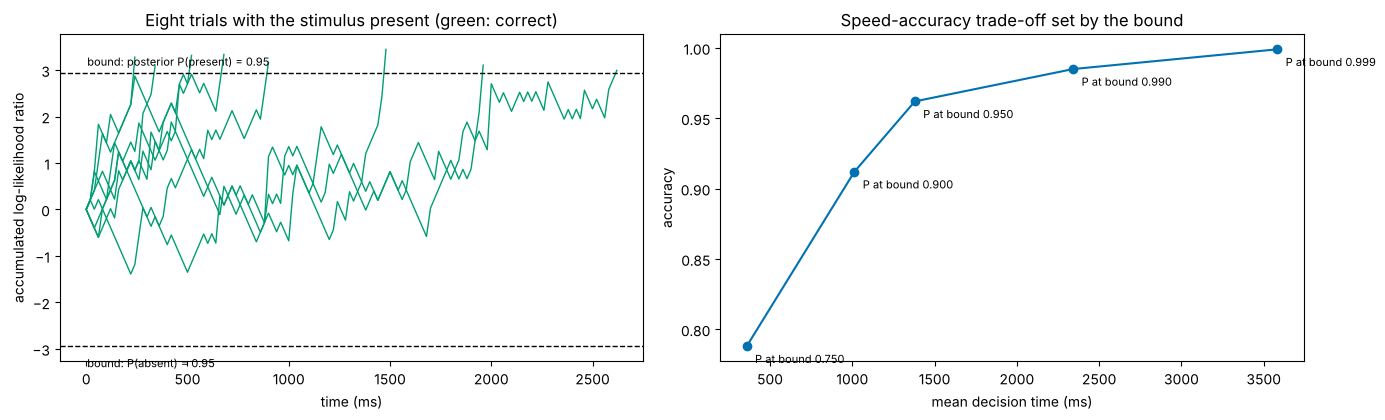

In [5]:
lam1, lam0 = 30 * 0.02, 20 * 0.02                                          # expected spikes per 20 ms bin under H1, H0
def sprt(stimulus_present, bound, rng, max_bins=2000):
    # Accumulate Poisson log-likelihood ratios bin by bin until |sum| >= bound. Returns (decision, number of bins, path).
    s, path = 0.0, [0.0]
    for t in range(1, max_bins + 1):
        x = rng.poisson(lam1 if stimulus_present else lam0)
        s += x * np.log(lam1 / lam0) - (lam1 - lam0)
        path.append(s)
        if abs(s) >= bound:
            return s > 0, t, np.array(path)
    return s > 0, max_bins, np.array(path)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for i in range(8):
    dec, t, path = sprt(True, np.log(19), RNG)
    axes[0].plot(np.arange(path.size) * 20, path, color=PALETTE[2] if dec else PALETTE[1], lw=1)
axes[0].axhline(np.log(19), color='black', ls='--', lw=1); axes[0].axhline(-np.log(19), color='black', ls='--', lw=1)
axes[0].text(5, np.log(19) + 0.15, 'bound: posterior P(present) = 0.95', fontsize=8); axes[0].text(5, -np.log(19) - 0.45, 'bound: P(absent) = 0.95', fontsize=8)
axes[0].set_xlabel('time (ms)'); axes[0].set_ylabel('accumulated log-likelihood ratio'); axes[0].set_title('Eight trials with the stimulus present (green: correct)')

print(f"{'bound a':>8}{'posterior at bound':>20}{'accuracy':>10}{'mean decision time (ms)':>25}")
bounds = [np.log(3), np.log(9), np.log(19), np.log(99), np.log(999)]
accs, times = [], []
for a in bounds:
    res = [sprt(bool(i % 2), a, RNG) for i in range(1000)]                  # half the trials with the stimulus present
    acc = np.mean([r[0] == bool(i % 2) for i, r in enumerate(res)]); mt = np.mean([r[1] for r in res]) * 20
    accs.append(acc); times.append(mt)
    print(f"{a:>8.2f}{1 / (1 + np.exp(-a)):>20.3f}{acc:>10.3f}{mt:>25.0f}")
axes[1].plot(times, accs, 'o-', color=PALETTE[0], lw=1.5)
for a, t, ac in zip(bounds, times, accs):
    axes[1].annotate(f'P at bound {1 / (1 + np.exp(-a)):.3f}', (t, ac), xytext=(6, -12), textcoords='offset points', fontsize=8)
axes[1].set_xlabel('mean decision time (ms)'); axes[1].set_ylabel('accuracy'); axes[1].set_title('Speed-accuracy trade-off set by the bound')
plt.tight_layout(); plt.show()

Each path is a random walk that drifts upwards when the stimulus is present (spikes are more frequent, so each bin's log-LR is on average positive). With a bound at $\log 19$, the accumulated evidence makes the posterior probability 0.95 when the bound is reached, and the accuracy is close to that (the walk can overshoot the bound, so accuracy is slightly higher). Raising the bound buys accuracy with time, the **speed–accuracy trade-off** observed in human and animal decisions. Note the assumption that made the sum valid: counts in different bins are independent given the hypothesis.

#### Interactive version: accumulating evidence
The slider changes the bound; each frame shows 20 simulated trials with the stimulus present.

In [6]:
bnds = [0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0]
def sprt_frame(a):
    rr = np.random.default_rng(int(a * 10))
    out = [sprt(True, a, rr, max_bins=400) for _ in range(20)]
    xs, ys = [], []
    for dec, t, path in out:
        xs += list(np.arange(path.size) * 20) + [None]; ys += list(np.round(path, 3)) + [None]
    return xs, ys, np.mean([o[0] for o in out]), np.mean([o[1] for o in out]) * 20
x0, y0, a0, t0 = sprt_frame(bnds[0])
fig_s = go.Figure([go.Scatter(x=x0, y=y0, mode='lines', line=dict(color=PALETTE[0], width=1), name='20 trials (stimulus present)'),
                   go.Scatter(x=[0, 3000], y=[bnds[0]] * 2, mode='lines', line=dict(color='black', dash='dash'), name='+bound'),
                   go.Scatter(x=[0, 3000], y=[-bnds[0]] * 2, mode='lines', line=dict(color='black', dash='dash'), name='-bound')])
fr = []
for i, a in enumerate(bnds):
    xs, ys, acc, mt = sprt_frame(a)
    fr.append(go.Frame(name=str(i), data=[go.Scatter(x=xs, y=ys), go.Scatter(y=[a, a]), go.Scatter(y=[-a, -a])], traces=[0, 1, 2],
                       layout=go.Layout(title=f'bound {a}: posterior at the bound {1 / (1 + np.exp(-a)):.3f};  correct {acc:.0%} of these 20 trials, mean time {mt:.0f} ms')))
fig_s.frames = fr
buttons, sliders = play_pause_and_slider(bnds, prefix='bound = ', duration=700)
fig_s.update_layout(title=fr[0].layout.title.text, xaxis=dict(title='time (ms)', range=[0, 3000]), yaxis=dict(title='accumulated log-LR', range=[-7, 7]),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_s.show(config=PLOTLY_CONFIG)

# **Part 3: Posterior Distributions over a Parameter**

When the hypothesis is a continuous parameter $\theta$ (a success probability, a firing rate), Bayes' rule holds with densities:

$$p(\theta \mid D) = \frac{P(D \mid \theta)\,p(\theta)}{\int P(D \mid \theta')\,p(\theta')\,d\theta'} .$$

The posterior $p(\theta \mid D)$ is a full distribution over the parameter: not one number, but a statement of which values remain plausible. It can be computed on a **grid** (evaluate likelihood × prior at many values of $\theta$ and normalise by the trapezoid rule, Lesson 13), or, for some prior–likelihood pairs, **exactly**.

### The beta–binomial model
- Generative model: $p \sim \operatorname{Beta}(\alpha, \beta)$, then $K \mid p \sim \operatorname{Binomial}(n, p)$.
- The beta density is $p(p) \propto p^{\alpha - 1}(1 - p)^{\beta - 1}$ on $[0, 1]$; $\operatorname{Beta}(1, 1)$ is uniform. Its mean is $\alpha/(\alpha + \beta)$.
- Multiplying by the likelihood $p^k(1 - p)^{n - k}$ gives the same form:

$$p \mid K = k\ \sim\ \operatorname{Beta}(\alpha + k,\ \beta + n - k).$$

The prior acts like $\alpha$ earlier successes and $\beta$ earlier failures (**pseudo-counts**). A prior and likelihood that give a posterior of the prior's form are called **conjugate**.

### The gamma–Poisson model
- $\lambda \sim \operatorname{Gamma}(a, b)$ (shape $a$, rate $b$, mean $a/b$), counts $x_1, \dots, x_m \mid \lambda$ independent Poisson: $\lambda \mid x \sim \operatorname{Gamma}(a + \sum_i x_i,\ b + m)$.

grid posterior vs conjugate Beta(11, 5): max |difference| = 8.0e-15
sequential: Beta(11, 5);  batch: Beta(11, 5)


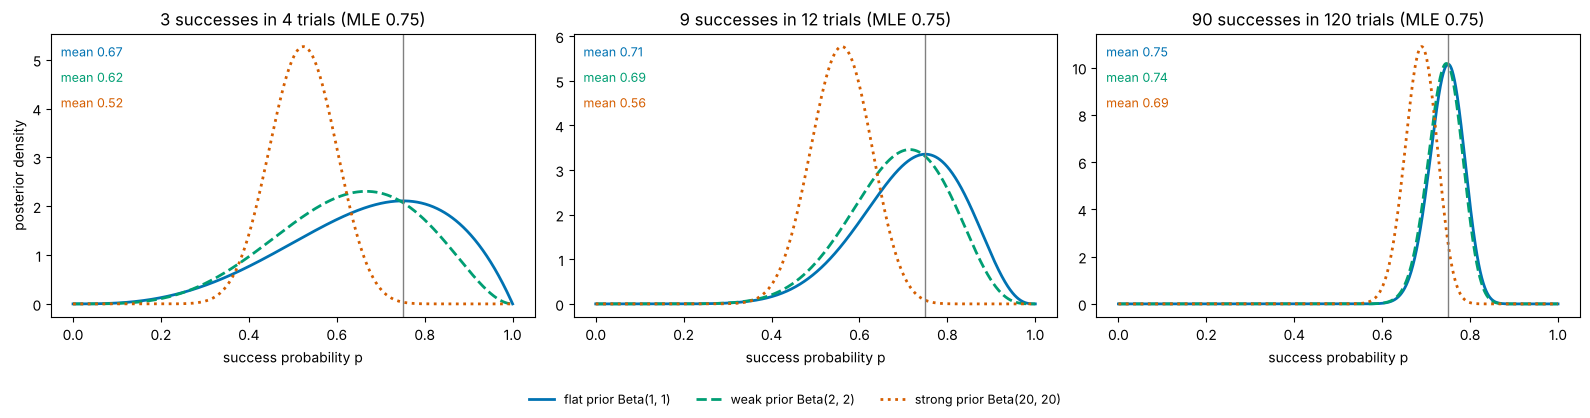

In [7]:
p_grid = np.linspace(0, 1, 2001)
def grid_posterior(k, n, alpha, beta):
    prior = stats.beta.pdf(p_grid, alpha, beta)
    lik = stats.binom.pmf(k, n, p_grid)
    unnorm = lik * prior
    return unnorm / np.trapezoid(unnorm, p_grid)

k_obs, n_obs = 9, 12
post_grid = grid_posterior(k_obs, n_obs, 2, 2)
post_exact = stats.beta.pdf(p_grid, 2 + k_obs, 2 + n_obs - k_obs)
print(f"grid posterior vs conjugate Beta(11, 5): max |difference| = {np.max(np.abs(post_grid - post_exact)):.1e}")

# Sequential updating equals batch updating.
outcomes = np.array([1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1])                  # (12,) 9 successes
a_, b_ = 2.0, 2.0
for y in outcomes:
    a_, b_ = a_ + y, b_ + (1 - y)                                           # one trial at a time
print(f"sequential: Beta({a_:.0f}, {b_:.0f});  batch: Beta({2 + outcomes.sum()}, {2 + len(outcomes) - outcomes.sum()})")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (k, n) in zip(axes, [(3, 4), (9, 12), (90, 120)]):
    for (al, be), c, ls, lab in [((1, 1), PALETTE[0], '-', 'flat prior Beta(1, 1)'), ((2, 2), PALETTE[2], '--', 'weak prior Beta(2, 2)'), ((20, 20), PALETTE[1], ':', 'strong prior Beta(20, 20)')]:
        ax.plot(p_grid, stats.beta.pdf(p_grid, al + k, be + n - k), ls, color=c, lw=2, label=lab)
        ax.text(0.02, 0.92 - 0.09 * [(1, 1), (2, 2), (20, 20)].index((al, be)), f'mean {(al + k) / (al + be + n):.2f}', color=c, fontsize=9, transform=ax.transAxes)
    ax.axvline(k / n, color='grey', lw=1); ax.set_title(f'{k} successes in {n} trials (MLE {k / n:.2f})')
    ax.set_xlabel('success probability p')
axes[0].set_ylabel('posterior density')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=9, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.show()

With 4 trials the prior matters a lot: a strong prior centred on 0.5 holds the posterior near 0.5 whatever the data say. With 120 trials all three posteriors are almost the same and sit at the MLE: **the data overwhelm the prior** as they accumulate. A prior is not a cheat to be avoided; it is an explicit, checkable assumption, and its influence can always be measured by trying several.

#### Interactive version: watching the posterior learn
The slider adds one trial at a time from a mouse that is correct with probability 0.75 (flat prior).

In [8]:
seq = (np.random.default_rng(3).random(60) < 0.75).astype(int)            # (60,) simulated outcomes
ns = [0, 1, 2, 3, 5, 8, 12, 20, 30, 45, 60]
fig_p = go.Figure([go.Scatter(x=p_grid[::10], y=np.round(stats.beta.pdf(p_grid[::10], 1, 1), 4), mode='lines', line=dict(color=PALETTE[0], width=3), name='posterior'),
                   go.Scatter(x=[0.75, 0.75], y=[0, 9], mode='lines', line=dict(color='grey', dash='dot'), name='true p = 0.75')])
fr = []
for i, n in enumerate(ns):
    k = int(seq[:n].sum())
    fr.append(go.Frame(name=str(i), traces=[0], data=[go.Scatter(y=np.round(stats.beta.pdf(p_grid[::10], 1 + k, 1 + n - k), 4))],
                       layout=go.Layout(title=f'{k} of {n} correct: posterior Beta({1 + k}, {1 + n - k}), mean {(1 + k) / (2 + n):.3f}, P(p > 0.5) = {stats.beta.sf(0.5, 1 + k, 1 + n - k):.3f}')))
fig_p.frames = fr
buttons, sliders = play_pause_and_slider(ns, prefix='trials = ', duration=600)
fig_p.update_layout(title=fr[0].layout.title.text, xaxis=dict(title='p'), yaxis=dict(title='posterior density', range=[0, 9]),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_p.show(config=PLOTLY_CONFIG)

# **Part 4: Summarising a Posterior**

A posterior distribution can be reported whole (a plot), or summarised:
- **MAP** (maximum a posteriori) estimate: the posterior's mode. With a flat prior, MAP = MLE.
- **Posterior mean**: $E[\theta \mid D]$; it minimises the expected **squared** error. For the beta–binomial, $(\alpha + k)/(\alpha + \beta + n)$; with a flat prior, $(k + 1)/(n + 2)$ (**Laplace's rule of succession**).
- **Posterior median**: minimises the expected **absolute** error.
- **Posterior probabilities** of statements of interest, such as $P(p > 0.5 \mid D)$: "how probable is it that the mouse is better than chance?"
- A **95% credible interval**: an interval holding 95% posterior probability, for example from the 2.5th to the 97.5th percentile. (Lesson 20 compares this with a confidence interval, which has a different meaning.)

For a symmetric posterior these summaries coincide; for a skewed one, which is typical with few data or estimates near 0 or 1, they differ, and the choice should be stated. When every one of $n$ trials goes the same way, the MLE is 1 and its Lesson 18 standard error is 0; the posterior mean is $(n + 1)/(n + 2) < 1$, and the posterior has width.

In [9]:
print(f"{'data':>9}{'MLE':>7}{'MAP':>7}{'mean':>7}{'median':>8}{'95% credible interval':>24}{'P(p > 0.5)':>12}   (flat prior)")
for k, n in [(3, 4), (9, 12), (20, 20), (0, 5), (90, 120)]:
    a, b = 1 + k, 1 + n - k
    mode = (a - 1) / (a + b - 2)
    lo, hi = stats.beta.ppf([0.025, 0.975], a, b)
    print(f"{k:>4}/{n:<4}{k / n:>7.3f}{mode:>7.3f}{a / (a + b):>7.3f}{stats.beta.median(a, b):>8.3f}{f'[{lo:.3f}, {hi:.3f}]':>24}{stats.beta.sf(0.5, a, b):>12.4f}")

# Gamma-Poisson: a neuron's rate from very few spikes.
counts_few = np.array([0, 2, 1, 0, 1])                                    # (5,) spikes in five 100 ms windows
a0, b0 = 2.0, 0.2                                                          # prior on the rate per window: mean 10 (100 spikes/s), wide
a_post, b_post = a0 + counts_few.sum(), b0 + counts_few.size
lam_grid = np.linspace(0, 5, 5001)
print(f"\nGamma-Poisson: MLE {counts_few.mean():.2f} spikes/window;  posterior Gamma({a_post:.0f}, {b_post:.1f}): mean {a_post / b_post:.3f}, "
      f"MAP {(a_post - 1) / b_post:.3f}, 95% interval {np.round(stats.gamma.ppf([0.025, 0.975], a_post, scale=1 / b_post), 3)} spikes/window")

     data    MLE    MAP   mean  median   95% credible interval  P(p > 0.5)   (flat prior)
   3/4     0.750  0.750  0.667   0.686          [0.284, 0.947]      0.8125
   9/12    0.750  0.750  0.714   0.725          [0.462, 0.909]      0.9539
  20/20    1.000  1.000  0.955   0.968          [0.839, 0.999]      1.0000
   0/5     0.000  0.000  0.143   0.109          [0.004, 0.459]      0.0156
  90/120   0.750  0.750  0.746   0.747          [0.665, 0.819]      1.0000

Gamma-Poisson: MLE 0.80 spikes/window;  posterior Gamma(6, 5.2): mean 1.154, MAP 0.962, 95% interval [0.423 2.244] spikes/window


Note the last rows of the beta table. 20 of 20 gives MLE 1 but posterior mean 0.955 and a credible interval reaching down to 0.84; 0 of 5 gives MLE 0 but a posterior mean of 0.14. The posterior keeps open the possibility that a perfect record was partly luck. In the gamma–Poisson example, five windows with four spikes give an MLE of 0.8 spikes per window; the posterior mean (about 1.15) is pulled towards the prior's large mean because five windows carry little information, and the interval shows how wide the uncertainty is.

# **Part 5: Decisions, Costs and Calibration**

### Expected loss
A decision rule chooses an action $a$ (say "present" or "absent") from the data. If the truth is $H$, the action costs $c(a, H)$. Given the posterior, the **expected loss** of each action is

$$\mathcal{L}(a \mid D) = \sum_H c(a, H)\,P(H \mid D),$$

and the **Bayes decision** chooses the action with the smallest expected loss (equivalently, the largest expected **utility** = negative loss). For two hypotheses, with zero cost for correct decisions, a miss costing $c_{\text{miss}}$ and a false alarm costing $c_{\text{FA}}$:

$$\text{say "present"} \iff c_{\text{miss}}\,P(H_1 \mid D) > c_{\text{FA}}\,P(H_0 \mid D) \iff P(H_1 \mid D) > \frac{c_{\text{FA}}}{c_{\text{FA}} + c_{\text{miss}}} .$$

- Equal costs: threshold 0.5. A miss costing 4 false alarms: threshold 0.2.
- In terms of the likelihood ratio: say "present" iff $\mathrm{LR} > \dfrac{c_{\text{FA}}}{c_{\text{miss}}}\cdot\dfrac{P(H_0)}{P(H_1)}$. **Rare signals and cheap misses both demand stronger evidence.** This is the decision-theoretic root of Lesson 16's threshold trade-off.

### Calibration
Posterior probabilities are only useful for decisions if they are **calibrated**: among all the cases given probability 0.8, about 80% should turn out true. A **reliability diagram** bins predictions by stated probability and plots the observed frequency in each bin against the mean prediction; a calibrated forecaster lies on the diagonal. Two scores reward calibrated, confident predictions:
- **log loss** (cross-entropy), $-\frac1n\sum_i[y_i\log q_i + (1 - y_i)\log(1 - q_i)]$, the negative Bernoulli log-likelihood of Lesson 18; one confident mistake ($q_i \approx 0$ when $y_i = 1$) can dominate it;
- **Brier score**, $\frac1n\sum_i(q_i - y_i)^2$.

miss costs 1, false alarm costs 1: say 'present' when P(present | data) > 0.50
miss costs 4, false alarm costs 1: say 'present' when P(present | data) > 0.20
miss costs 1, false alarm costs 4: say 'present' when P(present | data) > 0.80


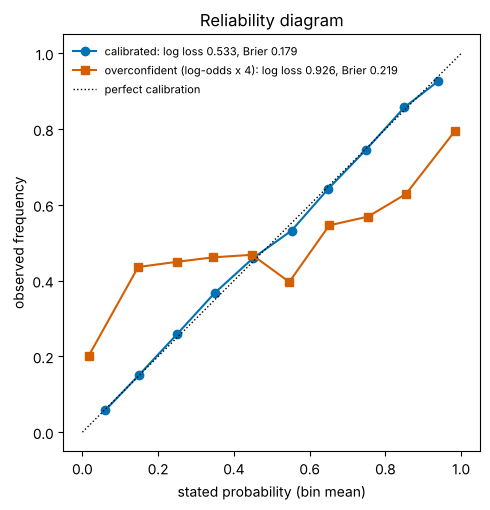

both forecasters rank the events identically, so their accuracy at threshold 0.5 is the same: 0.726 vs 0.726


In [10]:
def expected_loss_threshold(c_miss, c_fa):
    return c_fa / (c_fa + c_miss)

for c_miss, c_fa in [(1, 1), (4, 1), (1, 4)]:
    print(f"miss costs {c_miss}, false alarm costs {c_fa}: say 'present' when P(present | data) > {expected_loss_threshold(c_miss, c_fa):.2f}")

def reliability(q, y, edges=np.linspace(0, 1, 11)):
    # Mean predicted probability, observed frequency and count in each bin of predicted probability.
    q, y = np.asarray(q), np.asarray(y)
    idx = np.clip(np.digitize(q, edges) - 1, 0, len(edges) - 2)
    out = [(q[idx == b].mean(), y[idx == b].mean(), np.sum(idx == b)) for b in range(len(edges) - 1) if np.any(idx == b)]
    return np.array(out)

def log_loss(q, y, eps=1e-15):
    q = np.clip(q, eps, 1 - eps)
    return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))

# Two forecasters of the same events: one calibrated, one overconfident (its log-odds are 4 times too large).
true_logodds = RNG.normal(0, 1.5, 5000)                                    # (5000,) true log-odds of each event
y_ev = (RNG.random(5000) < expit(true_logodds)).astype(int)                 # (5000,) outcomes
q_cal, q_over = expit(true_logodds), expit(4 * true_logodds)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for q, c, mk, lab in [(q_cal, PALETTE[0], 'o', 'calibrated'), (q_over, PALETTE[1], 's', 'overconfident (log-odds x 4)')]:
    rel = reliability(q, y_ev)
    ax.plot(rel[:, 0], rel[:, 1], marker=mk, color=c, lw=1.5, label=f'{lab}: log loss {log_loss(q, y_ev):.3f}, Brier {np.mean((q - y_ev)**2):.3f}')
ax.plot([0, 1], [0, 1], 'k:', lw=1, label='perfect calibration')
ax.set_xlabel('stated probability (bin mean)'); ax.set_ylabel('observed frequency'); ax.set_aspect('equal')
ax.set_title('Reliability diagram'); ax.legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); plt.show()
print(f"both forecasters rank the events identically, so their accuracy at threshold 0.5 is the same: {np.mean((q_cal > 0.5) == y_ev):.3f} vs {np.mean((q_over > 0.5) == y_ev):.3f}")

The overconfident forecaster makes the **same** decisions at threshold 0.5 (it orders the events identically), so its accuracy is identical; but its stated probabilities are too extreme (an "0.95" comes true about 80% of the time), its log loss is much worse, and any decision with unequal costs or any combination with other evidence will be wrong. **Accuracy does not measure calibration.**

# **Part 6: Mini-Lab — A Bayesian Look at the Mouse and Its Visual Cortex**

### A. Posterior choice probabilities
Lesson 18 estimated the mouse's probability of turning right at each contrast difference $c = c_R - c_L$ and found three levels where every turn went one way, with a meaningless standard error of 0. Here each level gets a flat Beta(1, 1) prior and a Beta posterior.

     c     k/n    MLE post. mean   95% credible interval  P(p > 0.5 | data)
 -1.00    0/21  0.000      0.043          [0.001, 0.154]             0.0000
 -0.75    0/20  0.000      0.045          [0.001, 0.161]             0.0000
 -0.50    1/37  0.027      0.051          [0.006, 0.138]             0.0000
 -0.25    4/24  0.167      0.192          [0.068, 0.361]             0.0005
 +0.00   47/76  0.618      0.615          [0.506, 0.720]             0.9802
 +0.25   22/24  0.917      0.885          [0.740, 0.975]             1.0000
 +0.50   23/28  0.821      0.800          [0.642, 0.920]             0.9997
 +0.75   22/24  0.917      0.885          [0.740, 0.975]             1.0000
 +1.00   22/22  1.000      0.958          [0.852, 0.999]             1.0000


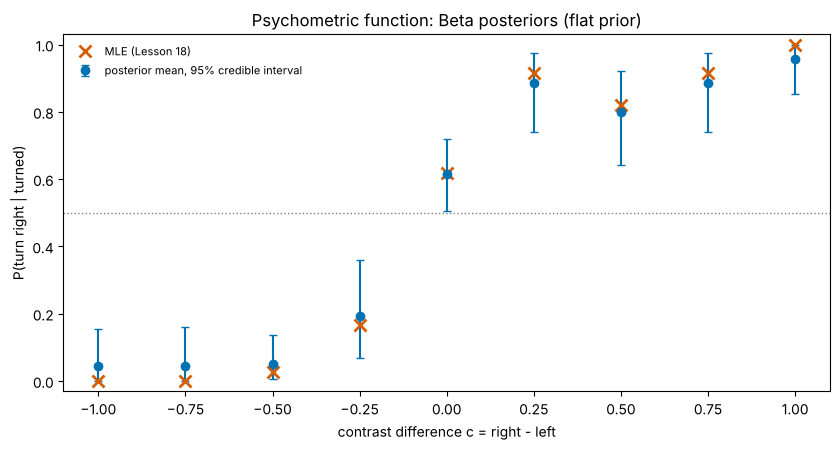

In [11]:
import os, urllib.request
STEIN_FILE = 'steinmetz_s11_lederberg.npz'
for cand in [STEIN_FILE, os.path.join('..', '..', 'data', STEIN_FILE)]:
    if os.path.exists(cand):
        stein_path = cand; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/8f9e0431a21d8ac0aa016e3502735f3b8627863a/data/' + STEIN_FILE, STEIN_FILE)
    stein_path = STEIN_FILE
dat = np.load(stein_path)
spk = dat['counts'].astype(float)                                          # (340, 698) spikes in 0.2 s
area = dat['brain_area']                                                   # (698,)
cl, cr, resp = dat['contrast_left'], dat['contrast_right'], dat['response']  # (340,) each
diff = np.round(cr - cl, 2); turned = resp != 0
levels = np.unique(diff)
n_c = np.array([np.sum(turned & (diff == c)) for c in levels])
k_c = np.array([np.sum((resp == -1) & (diff == c)) for c in levels])
a_c, b_c = 1 + k_c, 1 + n_c - k_c                                          # Beta posterior parameters, (9,) each
print(f"{'c':>6}{'k/n':>8}{'MLE':>7}{'post. mean':>11}{'95% credible interval':>24}{'P(p > 0.5 | data)':>19}")
for c, k, n, a, b in zip(levels, k_c, n_c, a_c, b_c):
    lo, hi = stats.beta.ppf([0.025, 0.975], a, b)
    print(f"{c:>+6.2f}{f'{k}/{n}':>8}{k / n:>7.3f}{a / (a + b):>11.3f}{f'[{lo:.3f}, {hi:.3f}]':>24}{stats.beta.sf(0.5, a, b):>19.4f}")
fig, ax = plt.subplots(figsize=(8.5, 4.6))
lo_c, hi_c = stats.beta.ppf(0.025, a_c, b_c), stats.beta.ppf(0.975, a_c, b_c)
mean_c = a_c / (a_c + b_c)
ax.errorbar(levels, mean_c, yerr=[mean_c - lo_c, hi_c - mean_c], fmt='o', color=PALETTE[0], capsize=3, label='posterior mean, 95% credible interval')
ax.plot(levels, k_c / n_c, 'x', color=PALETTE[1], ms=8, mew=2, label='MLE (Lesson 18)')
ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_xlabel('contrast difference c = right - left'); ax.set_ylabel('P(turn right | turned)'); ax.set_ylim(-0.03, 1.03)
ax.set_title('Psychometric function: Beta posteriors (flat prior)'); ax.legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

At $c = -1$ (0 of 21 right turns) the MLE is 0 with "SE 0"; the posterior mean is 0.043 and the 95% credible interval reaches 0.15: the mouse is very unlikely, but not certain, to turn right there. At $c = 0$ the posterior gives $P(p > 0.5 \mid \text{data}) \approx 0.98$: given a flat prior and these 76 turns, a rightward bias is very probable. That is a direct statement about the parameter, which Lesson 18's likelihood alone could not make.

### B. Decoding the stimulus from visual cortex with Bayes' rule
**The generative model ("naive Bayes").** Given whether a right grating is present ($R$) or absent, each of the 66 VISp neurons' counts is Poisson with its own mean, and neurons are **independent given the stimulus**. Then the log-likelihood ratio is a sum over neurons,

$$\log\frac{P(\mathbf{x} \mid R)}{P(\mathbf{x} \mid R^{c})} = \sum_{j=1}^{66}\Big[x_j\log\frac{\lambda_{j,1}}{\lambda_{j,0}} - (\lambda_{j,1} - \lambda_{j,0})\Big],$$

and the posterior is $P(R \mid \mathbf{x}) = \text{sigmoid}(\log \mathrm{LR} + \log O_{\text{prior}})$. The means $\lambda_{j,1}, \lambda_{j,0}$ and the prior are estimated from a random half of the trials (training); the decoder is evaluated on the other half.

In [12]:
visp = area == 'VISp'
X = spk[:, visp]                                                           # (340, 66) counts
R = cr > 0                                                                 # (340,) right grating present
perm = RNG.permutation(len(R)); tr = np.zeros(len(R), bool); tr[perm[:len(R) // 2]] = True; te = ~tr
eps = 0.1                                                                  # small pseudo-count so that no mean is exactly 0
lam_1 = (X[tr & R].sum(axis=0) + eps) / ((tr & R).sum() + eps)              # (66,) mean count given R
lam_0 = (X[tr & ~R].sum(axis=0) + eps) / ((tr & ~R).sum() + eps)            # (66,) mean count given not R
prior_R = R[tr].mean()
log_lr = (X * np.log(lam_1 / lam_0) - (lam_1 - lam_0)).sum(axis=1)          # (340,)
log_post_odds = log_lr + np.log(prior_R / (1 - prior_R))
post_R = expit(log_post_odds)                                              # (340,) P(R | counts)
decide = post_R > 0.5
print(f"training prior P(R) = {prior_R:.3f};  TEST accuracy {np.mean(decide[te] == R[te]):.3f}, hit rate {decide[te & R].mean():.3f}, false-alarm rate {decide[te & ~R].mean():.3f}")
print(f"median |log posterior odds| on test trials: {np.median(np.abs(log_post_odds[te])):.0f}  (a posterior of 1 - 1e-{np.median(np.abs(log_post_odds[te])) / np.log(10):.0f})")
print(f"test trials with posterior < 0.001 or > 0.999: {np.mean((post_R[te] < 0.001) | (post_R[te] > 0.999)):.1%}")
wrong = te & (decide != R)
print(f"test errors: {wrong.sum()};  their posteriors P(R | counts): {np.round(post_R[wrong], 4)};  truth: {R[wrong].astype(int)}")
print(f"test log loss {log_loss(post_R[te], R[te]):.3f}  (always predicting the base rate: {log_loss(np.full(te.sum(), prior_R), R[te]):.3f})")
extreme = te & ((post_R < 0.001) | (post_R > 0.999))
claimed = np.mean(np.minimum(post_R[extreme], 1 - post_R[extreme]))       # error rate the decoder itself expects on these trials
print(f"on the {extreme.sum()} test trials with posterior < 0.001 or > 0.999: the decoder expects an error rate of {claimed:.1e}, "
      f"observed {np.mean(decide[extreme] != R[extreme]):.3f} ({np.sum(decide[extreme] != R[extreme])} errors)")

training prior P(R) = 0.488;  TEST accuracy 0.976, hit rate 0.956, false-alarm rate 0.000
median |log posterior odds| on test trials: 49  (a posterior of 1 - 1e-21)
test trials with posterior < 0.001 or > 0.999: 97.6%
test errors: 4;  their posteriors P(R | counts): [0.0006 0.     0.1092 0.0723];  truth: [1 1 1 1]
test log loss 0.174  (always predicting the base rate: 0.695)
on the 166 test trials with posterior < 0.001 or > 0.999: the decoder expects an error rate of 1.4e-05, observed 0.012 (2 errors)


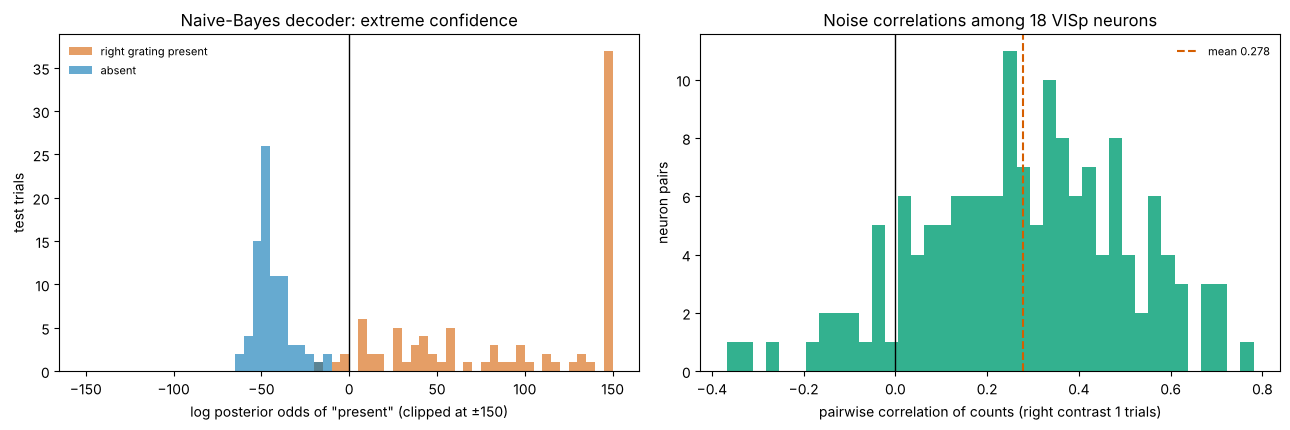

pairs: 153;  fraction of correlations above 0: 0.89


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].hist(np.clip(log_post_odds[te & R], -150, 150), bins=np.linspace(-150, 150, 61), color=PALETTE[1], alpha=0.6, label='right grating present')
axes[0].hist(np.clip(log_post_odds[te & ~R], -150, 150), bins=np.linspace(-150, 150, 61), color=PALETTE[0], alpha=0.6, label='absent')
axes[0].axvline(0, color='black', lw=1)
axes[0].set_xlabel('log posterior odds of "present" (clipped at ±150)'); axes[0].set_ylabel('test trials')
axes[0].set_title('Naive-Bayes decoder: extreme confidence'); axes[0].legend(fontsize=8, frameon=False)
# Pairwise noise correlations of VISp neurons within a condition (the assumption the decoder ignores).
Xa = X[cr == 1]; keep = Xa.mean(axis=0) >= 1.0                              # full-contrast right gratings: one fixed condition
cc = np.corrcoef(Xa[:, keep], rowvar=False)[np.triu_indices(keep.sum(), 1)]
axes[1].hist(cc, bins=40, color=PALETTE[2], alpha=0.8)
axes[1].axvline(0, color='black', lw=1); axes[1].axvline(cc.mean(), color=PALETTE[1], ls='--', label=f'mean {cc.mean():.3f}')
axes[1].set_xlabel('pairwise correlation of counts (right contrast 1 trials)'); axes[1].set_ylabel('neuron pairs')
axes[1].set_title(f'Noise correlations among {keep.sum()} VISp neurons'); axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
print(f"pairs: {cc.size};  fraction of correlations above 0: {np.mean(cc > 0):.2f}")

**Reading the decoder.**
- **Accurate.** On held-out trials the decoder is right about 98% of the time, better than Lesson 16's summed-count threshold, because it weights each neuron by how informative it is.
- **Badly miscalibrated.** Its median log-odds is about 49: it claims certainty of about $1 - 10^{-21}$ on a typical trial. On the 166 test trials where it claims more than 99.9% certainty, it expects about 0.002 errors in total and makes 2: an error rate roughly a thousand times higher than it states. Those two confident mistakes (posteriors of 0.0006 and below $10^{-4}$ for gratings that were present) account for most of its log loss. Such probabilities cannot be combined with other evidence or with costs: no realistic cost ratio would move a decision.
- **Why.** The model treats 66 neurons as 66 **independent** witnesses, multiplying their likelihood ratios. But the neurons share fluctuations (the right panel: among the 18 neurons firing at least one spike per window on full-contrast trials, 89% of pairwise noise correlations are positive, with mean 0.28, as in Lesson 17), so they are not independent witnesses. Multiplying correlated evidence as if it were independent double-counts it, and the log-odds grow far too large. The **posterior is correct only if the generative model is**; here the decision boundary is good but the probabilities are not.
- **What would help.** A model of the covariance (a multivariate Gaussian on transformed counts, or a GLM with coupling, Lesson 12), or recalibrating the log-odds on held-out data (shrinking them by a fitted factor, "temperature scaling" in machine learning). With 170 test trials and 3 errors, there is too little data here to calibrate reliably, which is itself a lesson.

**Limitations.** One session; one 200 ms window; a random half split; the decoder ignores contrast (it treats 0.25 and 1 alike as "present").

# **Part 7: Applications in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Bayes' rule | perception as inference (combining sensory evidence with priors); Bayesian decoding of stimuli and movements | probabilistic classifiers; naive Bayes; posterior inference |
| Odds and likelihood ratios | evidence accumulation (drift diffusion, LIP ramping); signal detection theory | logistic regression (log-odds linear in features); the logit output layer |
| Sequential updating | perceptual decisions over time; Kalman-filter decoders for brain–computer interfaces | online learning; filtering; recurrent state estimation |
| Posterior over parameters | psychometric function fits; estimating rates from few spikes; simulation-based inference of model parameters | Bayesian neural networks; Gaussian processes; uncertainty estimates |
| Priors and shrinkage | priors on tuning, regularised receptive fields (ridge = Gaussian prior, Lesson 15) | weight decay as a prior; MAP training |
| MAP vs posterior mean | point estimates from posteriors under different losses | MAP training vs Bayesian averaging |
| Expected loss, thresholds | choice under asymmetric rewards; criterion shifts | cost-sensitive classification; operating points |
| Calibration | reliability of confidence reports; decoder confidence | calibration of classifiers; temperature scaling; reliability diagrams |

# **Part 8: Summary, Exit Ticket and Lesson 20 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Bayes' rule | $P(H \mid D) = P(D \mid H)P(H)/P(D)$ | posterior ∝ likelihood × prior; normalise by the sum |
| Odds form | posterior odds = LR × prior odds | log-LRs add for conditionally independent data |
| Sequential updating | today's posterior is tomorrow's prior | same answer as all data at once |
| Beta–binomial | $\operatorname{Beta}(\alpha + k, \beta + n - k)$ | prior = pseudo-counts; flat prior mean $(k + 1)/(n + 2)$ |
| Gamma–Poisson | $\operatorname{Gamma}(a + \sum x, b + m)$ | rates from few counts |
| Summaries | MAP, mean, median, $P(\theta > c \mid D)$, credible interval | state which; they differ for skewed posteriors |
| Bayes decision | act if $P(H_1 \mid D) > c_{\text{FA}}/(c_{\text{FA}} + c_{\text{miss}})$ | priors and costs set the threshold |
| Calibration | reliability diagram; log loss; Brier | accuracy does not measure calibration; posteriors inherit model errors |

**Exit ticket.** A decoder built from 100 neurons, assumed independent given the stimulus, reports $P(\text{stimulus A}) = 0.9999$ on a trial where stimulus B was shown. Give two explanations and one way to check which applies.

*(Suggested answer: the model's independence assumption ignores shared variability, so evidence is double-counted and posteriors are too extreme (miscalibration); or the trial is genuinely unusual (the neurons really did respond as to A, through attention, movement or a recording artefact). Check calibration on held-out trials with a reliability diagram: if many "0.9999" predictions are wrong, the probabilities are overconfident and the model, not the trial, is at fault.)*

**Lesson 20 — Inference and model checking.** Bayesian posteriors are one answer to "how uncertain is this estimate?". Lesson 20 gives the other main answer: sampling variability, standard errors, bootstrap confidence intervals, and ROC curves for evaluating decoders like this one across all thresholds.

**Further reading.** J. K. Blitzstein and J. Hwang, *Introduction to Probability*, 2nd ed. (2019), Chapters 2 and 8; A. Gelman et al., *Bayesian Data Analysis*, 3rd ed. (2013), Chapters 1–2; J. I. Gold and M. N. Shadlen, "The neural basis of decision making", *Annual Review of Neuroscience* 30 (2007); D. C. Knill and A. Pouget, "The Bayesian brain", *Trends in Neurosciences* 27 (2004); C. Guo et al., "On calibration of modern neural networks", *ICML* (2017).